In [ ]:
import os
from datetime import datetime
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from wordcloud import WordCloud
import matplotlib.pyplot as plt

pd.set_option('future.no_silent_downcasting', True)

data_folder = Path(".")
file_pattern = "2025-10-InfoSec-Worker-Survey-Normalised-Published.csv"

likert_order = {
    "Strongly Disagree": 1,
    "Disagree": 2,
    "Neutral": 3,
    "Agree": 4,
    "Strongly Agree": 5
}

likert_columns = [
    "My job feels meaningful.",
    "My work directly improves the security of people or systems.",
    "A significant part of my work is done for appearances rather than real impact.",
    "If my job disappeared tomorrow, things would get worse for someone.",
    "My work is constrained by bureaucracy or political posturing.",
    "Security would improve if fewer people had jobs like mine.",
    "I spend more time explaining or justifying my work than doing it.",
]

demographic_column_map = {
    "Age Range": "Age",
    "Gender": "Gender",
    "What is your average personal income (after tax)?": "Income",
    "Which country do you currently live in or spend most of your time working from?": "Country",
    "What best describes your current industry or sector?": "Industry",
    "Years of Industry Experience": "Experience"
}


In [2]:
pastel_colors = [
    "#F5A9A9",  # Dusty rose
    "#F5CBA7",  # Warm peach
    "#B4D8A8",  # Gentle sage
    "#A7C8E1",  # Calm sky
    "#B9A4D6",  # Muted lavender
    "#E5CFA4",  # Soft golden cream
    "#E1B875",  # Warm apricot
    "#B6D1B8"  # Gentle moss
]

pio.templates["pastels"] = pio.templates["plotly"].update({
    "layout": {
        "font": {"family": "Poppins, Quicksand, Arial", "size": 14, "color": "#4A4A4A"},
        "paper_bgcolor": "#FFF",
        "plot_bgcolor": "#FFF",
        "colorway": pastel_colors,
        "title": {"x": 0.5, "font": {"size": 20, "color": "#4A4A4A"}},
        "xaxis": {
            "gridcolor": "#f2e9e4",
            "zerolinecolor": "#f2e9e4",
            "linecolor": "#e5dcd2",
            "title_font": {"size": 14, "color": "#4A4A4A"},
            "tickfont": {"color": "#4A4A4A"}
        },
        "yaxis": {
            "gridcolor": "#f2e9e4",
            "zerolinecolor": "#f2e9e4",
            "linecolor": "#e5dcd2",
            "title_font": {"size": 14, "color": "#4A4A4A"},
            "tickfont": {"color": "#4A4A4A"}
        },
        "legend": {
            "bgcolor": "rgba(255,255,255,0.6)",
            "bordercolor": "rgba(0,0,0,0)",
            "font": {"color": "#4A4A4A"}
        }
    }
})

pio.templates.default = "pastels"
pio.renderers.default = "notebook_connected"

In [ ]:
files = list(data_folder.glob(file_pattern))

if not files:
    raise FileNotFoundError("No matching survey CSV files found in the 'data/' folder.")

# Sort files by modification time (newest last)
files.sort(key=os.path.getmtime, reverse=True)
latest_file = files[0]

modified_time = datetime.fromtimestamp(os.path.getmtime(latest_file)).strftime('%Y-%m-%d %H:%M:%S')

df = pd.read_csv(latest_file)
df = df.rename(columns=demographic_column_map)

## Introduction

Between June and September 2025, I ran a small, community-driven survey exploring how InfoSec professionals feel about their work, in particular, in relation to meaning, value, and the idea of "bullshit jobs". The survey was self-selecting and shared across Reddit, Mastodon, and Bluesky, inviting
 anyone working in or adjacent to InfoSec to participate.

In total, 118 responses were collected; I also conducted 11 follow-up interviews with volunteers who wanted to expand on their answers. To protect participants’ privacy, long-form written responses and interview transcripts are not included in this notebook or the published survey results.

This research is exploratory rather than conclusive, and while the sample size is small and not representative of the industry as a whole, the aim was to create space for anonymous honesty: a chance for people to reflect, vent, or question the meaning of their work without a professional
consequence or moralising.

A separate, more reflective piece expanding on my conference talk will be published later. That work will focus on interpretation and cultural context.

As a standard disclaimer: I’m not a sociologist or policy analyst. I scraped through Discrete Maths at university. I'm a security engineer by
trade, and I’ve spent nearly a week fist-fighting Plotly and Pandas. You can find all the code used to generate this report [on Gitlab](https://gitlab.com/errbufferoverfl/garden-errbufferoverfl-me/blob/hugo/notebook/2025/11/11/bullshit-jobs-survey-findings.qmd).

## Data Overview / Demographics

The below map shows the geographic distribution of survey respondents. The majority of participants were based in English-speaking countries, particularly the United States, Australia, Canada, and the United Kingdom. Smaller clusters of responses came from Europe, India, and parts of Southeast Asia, with only a handful from other regions.

The concentration in a few countries reflects not only the language and cultural reach of the platforms where the survey was shared (Reddit, Mastodon, and Bluesky), but also my own social and professional networks. As a white Australian working in InfoSec, most of my online followers, friends, and
professional contacts are also white Australians or from similar English-speaking contexts. This inevitably shapes who sees and responds to the survey.

The sample is not globally representative, it offers valuable insight into how professionals in these regions perceive meaning, bureaucracy, and purpose within their work. The relatively even participation across North America and Oceania also provides enough variation to explore differences by
context and industry culture, even if broader regional generalisations are inappropriate.

In [ ]:
pastel_scale = [
    "#F5A9A9",  # Dusty rose
    "#F5CBA7",  # Warm peach
    "#E5CFA4",  # Soft golden cream
    "#E1B875",  # Warm apricot
    "#B4D8A8",  # Gentle sage
    "#B6D1B8",  # Gentle moss
    "#A7C8E1",  # Calm sky
    "#B9A4D6",  # Muted lavender
]

country_counts = df["Country"].value_counts().reset_index()
country_counts.columns = ["Country", "Count"]

fig = px.choropleth(
    country_counts,
    locations="Country",
    locationmode="country names",
    color="Count",
    color_continuous_scale=pastel_scale,
    title="Respondent count by country"
)

fig.show()

## Gender, Age & Experience

### Gender

When we breakdown the survey results by gender, we can see that the majority of respondents are male (72%). Women account for about 17%, while non-binary or gender-diverse respondents make up just over 5%. Another 5% preferred not to state their gender, and less than 1% chose to self-describe.

These participation rates seem to mirror broader trends within the InfoSec profession, which continues to be male-dominated despite improvements in representation in recent years. According to the [Global Cybersecurity Forum’s 2024 Cybersecurity Workforce Report](https://api.gcforum
.org/api/files/public/upload/8eaba644-0889-49b4-8c7d-8de3840decac_one-Cybersecurity-Workforce-Report-(002).pdf), women account for roughly 24% of the cybersecurity workforce.

The inclusion of respondents who identified as non-binary, gender-diverse, or who preferred not to disclose suggests that the survey successfully reached a somewhat broader range of identities than other traditional workplace studies. However, low participation rates in these groups mean that
when interpreting differences by gender in later analysis, results should be seen as indicative rather than statistically representative.

It would have been nice to hear from more women and non-binary or gender non-conforming (GNC) people, particularly because I’m interested in how "[glue work](https://www.noidea.dog/glue)", the invisible, coordination-heavy labour that keeps teams functioning contributes to feelings of "bullshit work".

From personal experience, women and gender-diverse professionals are disproportionately expected to take on this kind of relational or maintenance work: mentoring, stakeholder management, smoothing conflict, or keeping projects on track. While this work is often considered critical to the success
 of teams, it's often not formally valued or recognised especially within the context of promotion cycles.

Hearing more from participants in these positions would have offered a better understanding of whether  gendered expectations shape experiences of work in the security industry, and if so, how. Though, the absence of these voices is itself telling.

In [ ]:
fig_gender = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "bar"}, {"type": "domain"}]],
    subplot_titles=("Respondents by Gender", "Gender Distribution")
)

exp_counts = df["Gender"].value_counts().reset_index()
exp_counts.columns = ["Gender", "Count"]

bar_trace = go.Bar(
    x=exp_counts["Gender"],
    y=exp_counts["Count"],
    name="Gender Count"
)
fig_gender.add_trace(bar_trace, row=1, col=1)

pie_trace = go.Pie(
    labels=exp_counts["Gender"],
    values=exp_counts["Count"],
    name="Gender Distribution",
    textinfo="label+percent",
    hole=0.2
)
fig_gender.add_trace(pie_trace, row=1, col=2)

fig_gender.update_layout(
    title_text="Gender Distribution — Bar & Pie Comparison",
    title_x=0.5,
    showlegend=False,
    xaxis_title="Gender Group",
    yaxis_title="Count",
    height=1000,
)

fig_gender.show()

### Age

Most respondents were between 25 and 54 years old, with the largest group (33%) aged 35–44. This likely indicates that the majority of participants are mid-career and likely established professionals.

The small number of younger respondents (under 25) likely reflects both the self-selecting nature of the survey and the fact that entry into InfoSec work often follows several years of broader IT or technical experience. Similarly, the low representation of those aged 55 and older may reflect both
the relative youth of the cybersecurity field and career transitions into management or consulting roles.

The mid-career skew is important to consider. Because a majority of participants are likely to have had enough time in the industry to see structural inefficiencies and contradictions in their work. But may not have been in their roles long enough to identify tools and techniques that could
 be used to improve their work—a dynamic that might increase the feelings of frustration or futility.

Looking forward, it would be good to hear more from younger and late-career professionals, as well as those navigating non-traditional career paths. Their perspectives could offer valuable contrasts, from early-career gatekeeping and impostor syndrome to late-career burnout and exit
decisions. It would likely improve our understanding of how perceptions of "bullshit work" evolve over time.

In [6]:
fig_age = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "bar"}, {"type": "domain"}]],
    subplot_titles=("Respondents by Age Group", "Age Distribution")
)

exp_counts = df["Age"].value_counts().reset_index()
exp_counts.columns = ["Age", "Count"]

bar_trace = go.Bar(
    x=exp_counts["Age"],
    y=exp_counts["Count"],
    name="Age Count"
)
fig_age.add_trace(bar_trace, row=1, col=1)

pie_trace = go.Pie(
    labels=exp_counts["Age"],
    values=exp_counts["Count"],
    name="Age Distribution",
    textinfo="label+percent",
    hole=0.2
)
fig_age.add_trace(pie_trace, row=1, col=2)

fig_age.update_layout(
    title_text="Age Distribution — Bar & Pie Comparison",
    title_x=0.5,
    showlegend=False,
    xaxis_title="Age Group",
    yaxis_title="Count",
    height=1000,
)

fig_age.update_xaxes(categoryorder="array", categoryarray=["Under 25", "25-34", "35-44", "45-54", "55+"])
fig_age.show()

### Experience

Nearly half of respondents (45.8%) reported having 15 or more years of experience in InfoSec or closely related fields. Another 24% had 6–10 years, and 14% fell within the 3–5 year range. Only a small proportion (less than 2%) were early-career professionals with 0–2 years of experience.

This distribution mirrors the age data, where most participants were between 25 and 54 years old. Together, these findings show that the majority of survey participants have spent a reasonable amount of time in the industry and have likely experienced its cultural, structural, and technical
shifts to some degree.

It's important to remember that the predominance of mid- to late-career respondents will shape the tone of the survey: these are people who have seen enough of the industry to form opinions about meaning, bureaucracy, and burnout. Their reflections will be based on a mid to long-term awareness
 of how the InfoSec field operates and evolves, rather than only early-career frustrations.

It’s notable that so few of those starting their careers responded; it likely reflects the self-selecting nature of the survey and the way it circulated. It _might_ suggest that newer entrants are less likely
 to feel comfortable voicing dissatisfaction or lack the institutional perspective to frame it, it could also be a consequence of how the survey was circulated.

I was disappointed by the lack of early-career feedback. People who are just entering the field typically have fresh eyes: spotting the weird idiosyncrasies of our work and the inefficiencies that we've become accustomed to. Their perspectives would have been invaluable in uncovering how bullshit
 work can be normalised.

Looking ahead, it would be amazing to design a longitudinal study that follows early-career InfoSec professionals over several years, tracking how their perceptions of meaning, bureaucracy, and value evolve. This could help reveal whether cynicism and frustration accumulate over time, or whether
adaptation and agency reshape how people make sense of the "bullshit" embedded in their work.

::: callout-note
Anyway, if you're an early-career InfoSec professional and would be interested in participating in a future set of longitudinal interviews, you should reach out! I'd love to hear from you.
:::

In [ ]:
fig_exp = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "bar"}, {"type": "domain"}]],
    subplot_titles=("Respondents by Experience Group", "Experience Distribution")
)

exp_counts = df["Experience"].value_counts().reset_index()
exp_counts.columns = ["Experience", "Count"]

bar_trace = go.Bar(
    x=exp_counts["Experience"],
    y=exp_counts["Count"],
    name="Experience Count"
)
fig_exp.add_trace(bar_trace, row=1, col=1)

pie_trace = go.Pie(
    labels=exp_counts["Experience"],
    values=exp_counts["Count"],
    name="Experience Distribution",
    textinfo="label+percent",
    hole=0.2
)
fig_exp.add_trace(pie_trace, row=1, col=2)

fig_exp.update_layout(
    title_text="Experience Distribution — Bar & Pie Comparison",
    title_x=0.5,
    showlegend=False,
    xaxis_title="Experience Group",
    yaxis_title="Count",
    height=1000,
)

fig_exp.update_xaxes(categoryorder="array", categoryarray=["0-2", "2-5", "3-5", "6-10", "11-15", "15+"])
fig_exp.show()


## Salary & Compensation

Almost half of all respondents (49.6%) reported working in the tech sector, making it the most represented industry in the survey. The next largest groups were finance (11.1%), healthcare (5.1%), defence (5.1%), and government (4.3%). Smaller proportions came from manufacturing, education,
insurance, and research, while a handful of respondents worked across non-profit, logistics, and other sectors. Around 7.7% preferred not to disclose their industry.

The tech bias isn’t surprising; a lot of InfoSec work happens inside SaaS companies, cloud platforms, software dev shops, and the general “tech-ish” ecosystem.

It’s also worth remembering that most of the participants likely work in private companies, which tend to be driven by things like shareholder value, growth, and staying out of the news for bad security practice. Though as Graeber points out in Bullshit Jobs, privatisation doesn’t magically make you immune to bullshit.

So it's probably fair to say the answers here are naturally going to reflect corporate and tech-oriented contexts more than anything else. It would be good to hear more from participants in other industries, particularly those with more traditional, mission-driven structures.

In [ ]:
fig_industry = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "bar"}, {"type": "domain"}]],
    subplot_titles=("Respondents by Industry", "Industry Distribution"),
)

industry_counts = df["Industry"].value_counts().reset_index()
industry_counts.columns = ["Industry", "Count"]

industry_bar_trace = go.Bar(
    x=industry_counts["Industry"],
    y=industry_counts["Count"],
    name="Industry Count"
)
fig_industry.add_trace(industry_bar_trace, row=1, col=1)

industry_pie_trace = go.Pie(
    labels=industry_counts["Industry"],
    values=industry_counts["Count"],
    name="Industry Distribution",
    textinfo="label+percent",
    hole=0.2
)
fig_industry.add_trace(industry_pie_trace, row=1, col=2)

fig_industry.update_layout(
    title_text="Industry Distribution — Bar & Pie Comparison",
    title_x=0.5,
    showlegend=False,
    xaxis_title="Industry Group",
    yaxis_title="Count",
    height=1000,
)

fig_industry.update_xaxes(categoryorder="array")
fig_industry.show()

### Salary

All results are in AUD. Almost half of respondents (44.1%) said they earn over $200,000 a year, which puts them firmly at the top end of the Australian (and global) InfoSec pay scale. Another 16.1% reported earning between $100,000 - $149,999, and 14.4% fell into the $150,000 - $199,999
range. So, roughly three-quarters of people who took this survey make more than $100k a year.

A smaller group reported incomes between $80,000 - $99,999 (4.2%), and hardly anyone was below $80k. That probably reflects both the seniority of the group and the fact that InfoSec just… pays well. Around 18.6% didn’t want to share their income at all, which is fair enough.

I also didn’t ask whether people receive on-call pay, bonuses, equity, or other benefits that can bump their actual income higher, so these numbers likely sit a bit under what many people really take home.

This salary spread matches the general vibe of the cohort: most respondents were mid- to late-career, with a decade or more of experience, so the higher pay brackets make sense. What it doesn’t give us is much insight into early-career folks, who are more likely to be in the lower brackets and
may have very different feelings about their pay in contrast to the amount of "bullshit" work they do.

I wouldn’t be shocked if higher income softens the feeling that your job is bullshit (to a point). Money can take the edge off stress, but it only goes so far. An [SBS article](https://www.sbs.com.au/news/article/how-much-money-do-you-need-to-be-happy/4wiladly5) from 2025 summarises a study showing well-being peaks around $75,000 USD (about $167,000 AUD today). After that, extra salary doesn’t do as much for happiness.

David Hinkle makes a similar point in _Less is More_: after a certain threshold, more money or more "growth" doesn’t reliably make people better off. A lot of high-income workers are already past that line.

So, in the context of this survey, having a comfortable income probably helps people feel less stressed, but it doesn’t magically protect anyone from the existential dread of feeling like their work might be pointless.

In [9]:
fig_income = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "bar"}, {"type": "domain"}]],
    subplot_titles=("Respondents by Income", "Income Distribution"),
)

income_counts = df["Income"].value_counts().reset_index()
income_counts.columns = ["Income", "Count"]

income_bar_trace = go.Bar(
    x=income_counts["Income"],
    y=income_counts["Count"],
    name="Income Count"
)
fig_income.add_trace(income_bar_trace, row=1, col=1)

income_pie_trace = go.Pie(
    labels=income_counts["Income"],
    values=income_counts["Count"],
    name="Income Distribution",
    textinfo="label+percent",
    hole=0.2
)
fig_income.add_trace(income_pie_trace, row=1, col=2)

fig_income.update_layout(
    title_text="Income Distribution — Bar & Pie Comparison",
    title_x=0.5,
    showlegend=False,
    xaxis_title="Income Group",
    yaxis_title="Count",
    height=1000,
)

fig_income.update_xaxes(categoryorder="array", categoryarray=["Under 20,000", "20,000-39,999", "40,000-59,999", "60,000-79,999", "80,000-99,999", "100,000-149,999", "150,000-199,999", "200,000+"])
fig_income.show()

## Perception of "Bullshit Jobs"

When asked directly whether they believed their job was a "bullshit job", most respondents stopped short of saying an outright "yes". Only 5 participants (4%) agreed that their job was entirely meaningless, while a majority, 58 respondents (49%) selected "Sometimes". Another 55 respondents (47%) said "No".

In [10]:
question_col = "Do you believe your job is a \"bullshit job\"?"
subset = df[[question_col, "Gender", "Age", "Income", "Country", "Experience"]]

overall_counts = subset[question_col].value_counts().reindex(["Yes", "Sometimes", "No"])

fig = px.bar(
    overall_counts,
    x=overall_counts.index,
    y=overall_counts.values,
    text=overall_counts.values,
    title="Do you believe your job is a 'bullshit job'? — Overall",
    labels={"x": "Response", "y": "Number of Respondents"},
    color=overall_counts.index,
)

fig.update_traces(textposition="outside")
fig.update_layout(showlegend=False)
fig.show()

This distribution suggests that while few InfoSec professionals see their work as completely devoid of purpose, many experience periodic or situational feelings of futility. The large proportion of "Sometimes" responses hints at a tension between knowing their work has value in theory and feeling that value is undermined in practice, whether through bureaucracy, organisational politics, or performative processes that disconnect effort from impact. These results align with broader findings in the Likert-scale data, where respondents expressed both a belief that their jobs are meaningful and frustration that much of their effort is spent on administrative or symbolic work. Taken together, this chart reinforces the idea that information security work is rarely "bullshit" in itself, but that the structures surrounding it often make it feel that way.

These results align with broader findings in the Likert-scale data, where respondents expressed both a belief that their jobs are meaningful and frustration that much of their effort is spent on administrative or symbolic work. Taken together, this chart reinforces the idea that information security work is rarely "bullshit" in itself, but that the structures surrounding it often make it feel that way.

### By Gender

When broken down by gender, the overall pattern remains consistent: most respondents answered "Sometimes" or "No", rather than a definitive "Yes".

Among men, responses were almost evenly split between "Sometimes" and “No,” suggesting that while many experience moments of frustration or futility, few feel their roles are entirely meaningless. Women were somewhat more likely than men to select “Sometimes,” indicating a slightly higher degree of ambivalence about the value or structure of their work.

A small number of non-binary and gender-diverse respondents also leaned toward "Sometimes", though the sample size here is too small for strong conclusions. Althought there is limited data I think it reflects a shared undercurrent across groups, that the issue isn’t about total meaninglessness, but about periodic disconnection between the purpose of security work and how it is practiced day-to-day.

These results align with existing discussions around "glue work" and gendered labour: women and gender-diverse professionals may be more likely to shoulder invisible coordination, communication, or compliance tasks, the kind of work that can feel essential but undervalued. This may contribute to greater moments of perceived "bullshit" even when the work itself serves an important function.

Overall, while no gender group overwhelmingly identifies their work as wholly "bullshit", the differences in degree of ambivalence hint at how role expectations and recognition may intersect with identity to shape how meaning (or futility) is experienced in the field.

In [11]:
fig = px.histogram(
    subset,
    x=question_col,
    color="Gender",
    barmode="group",
    category_orders={question_col: ["Yes", "Sometimes", "No"]},
    title="Do you believe your job is a 'bullshit job'? — by Gender",
    labels={"x": "Response", "y": "Number of Respondents"},
)
fig.show()

### By Age

Across all age groups, the most common response was "Sometimes", followed closely by "No". This pattern mirrors the overall trend in the dataset, few respondents see their jobs as entirely meaningless, but many experience periodic or situational disillusionment.

The 35-44 and 45-54 age groups show the strongest presence in both "Sometimes" and "No" categories, reflecting the survey’s overall mid-career skew. These respondents are likely established enough in their roles to see the structural inefficiencies and contradictions in their work but may also have the experience or stability to find meaning despite them.

Participants aged 25-34 also lean heavily toward "Sometimes", suggesting that early- to mid-career professionals are grappling with similar frustrations: possibly around bureaucracy, internal politics, or unclear impact, but haven’t yet fully adapted or detached from them.

Very few respondents under 25 or over 55 participated, but those who did were split: a small handful of younger respondents answered "Sometimes" or "Yes", while a few older respondents leaned more toward "No". The limited representation makes it hard to generalise, but it hints that perceptions of meaning may shift with both time and stability in one’s career.

Taken together, this chart reinforces a key theme across the data: ambivalence is the dominant emotion. Most information security professionals don’t feel their work is entirely meaningless, but many see enough bureaucracy, repetition, or misalignment of purpose to question its value at times.

In [12]:
age_order = [
    "Under 25", 
    "25-34", 
    "35-44", 
    "45-54", 
    "55+"
]

fig = px.histogram(
    subset,
    x=question_col,
    color="Age",
    barmode="group",
    category_orders={
        question_col: ["Yes", "Sometimes", "No"],
        "Age": age_order
    },
    title="Do you believe your job is a 'bullshit job'? — by Age",
    labels={"x": "Response", "y": "Number of Respondents"},
)
fig.show()

### By Experience

When viewed through the lens of experience, the pattern remains broadly consistent: most respondents selected "Sometimes" or "No", regardless of how long they’ve worked in the field.

Those with 15+ years of experience form the largest group in both categories, suggesting that while veteran professionals may occasionally question the purpose or impact of their work, most ultimately find value or meaning in what they do.

This could reflect a degree of adaptation (or resignation) that develops over time, as experienced practitioners learn to navigate (or tolerate) organisational inefficiencies. I’d say it’s a little bit of both, if the responses are anything to go by: there’s a clear sense of resignation that some aspects of bullshit are simply part of the job, but also a kind of pragmatic adaptability, a drive to find workarounds, carve out meaning, or maintain effectiveness despite those structural frustrations.

Respondents with 6–10 years of experience also lean strongly toward "Sometimes" and "No", highlighting mid-career ambivalence as a shared theme. Meanwhile, the few early-career participants (0–2 years) were split, though their small numbers make it difficult to interpret confidently.

Across all groups, very few respondents identified their jobs as entirely "bullshit", but the persistence of "Sometimes" across every experience bracket suggests that feelings of futility aren’t tied to inexperience or cynicism, they’re structural. Even those with long tenures in the field occasionally feel that their labour is wasted, misdirected, or obscured by bureaucracy.

Taken together, the data implies that experience doesn’t eliminate disillusionment, it may only change how it’s rationalised or managed.

In [13]:
exp_order = [
    "0-2", 
    "2-5", 
    "3-5", 
    "6-10", 
    "11-15", 
    "15+"
]

fig = px.histogram(
    subset,
    x=question_col,
    color="Experience",
    barmode="group",
    category_orders={
        question_col: ["Yes", "Sometimes", "No"],
        "Experience": exp_order
    },
    title="Do you believe your job is a 'bullshit job'? — by Experience",
    labels={"x": "Response", "y": "Number of Respondents"},
)
fig.show()

### By Income

Across income groups, the majority of respondents selected "Sometimes" or "No", continuing the broader trend of ambivalence seen throughout the dataset. However, there are subtle differences that hint at how income may shape perceptions of meaning and frustration.

Respondents earning over \$200,000 AUD - the largest income group in the survey, were more likely to answer "No", suggesting that higher earners tend to view their work as meaningful or, at least, worthwhile. Meanwhile, those in the \$100,000-\$149,999 and \$150,000-\$199,999 ranges were more evenly split between "Sometimes" and "No", indicating that feelings of bullshit work persist even among well-compensated professionals.

Lower-income respondents were few in number, but among them there was a slightly higher proportion of "Sometimes" and occasional "Yes" responses. This may reflect greater exposure to bureaucratic, repetitive, or less visible forms of labour, the kind that can feel more disconnected from purpose or recognition.

Overall, the data supports the idea that higher income offers some insulation against feelings of futility, but not immunity. As discussed earlier, research suggests that money only improves well-being up to a certain point, roughly $167,000 AUD in today’s terms, after which its effects plateau. This aligns with the survey’s pattern: income may buffer against stress and insecurity, but does little to protect against existential dissatisfaction.

In [14]:
income_order = [
    "Under 20,000",
    "20,000-39,999",
    "40,000-59,999",
    "60,000-79,999",
    "80,000-99,999",
    "100,000-149,999",
    "150,000-199,999",
    "200,000+"
]

fig = px.histogram(
    subset,
    x=question_col,
    color="Income",
    barmode="group",
    category_orders={
        question_col: ["Yes", "Sometimes", "No"],
        "Income": income_order
    },
    title="Do you believe your job is a 'bullshit job'? — by Income",
    labels={"x": "Response", "y": "Number of Respondents"},
)
fig.show()

### By Country

Responses by country largely mirror the overall trend: most participants answered "Sometimes" or "No", with very few respondents in any region believing their job is entirely "bullshit".

The largest response groups came from Australia and the United States, and in both countries, the majority of participants selected "Sometimes". This suggests a shared sense of occasional disillusionment or frustration across regions, that is, professionals in both contexts recognise moments where their work feels performative, bureaucratic, or disconnected from impact, even if they do not see their roles as wholly meaningless.

Respondents from other countries, including the United Kingdom, Canada, and New Zealand, followed a similar distribution, though smaller sample sizes make it difficult to draw firm comparisons. The consistency across regions hints that feelings of futility in information security work transcend national or organisational boundaries, suggesting they stem less from local workplace culture and more from the structural nature of the industry itself, shaped by compliance frameworks, constant audit demands, and performative risk management.

While it would be interesting to explore how local economic or cultural factors influence these perceptions, this dataset points toward a shared professional experience: the sense that even in different countries and contexts, information security workers encounter the same contradictions between meaning, necessity, and bureaucracy.

In [15]:
fig = px.histogram(
    subset,
    x=question_col,
    color="Country",
    barmode="group",
    category_orders={
        question_col: ["Yes", "Sometimes", "No"],
    },
    title="Do you believe your job is a 'bullshit job'? — by Country",
    labels={"x": "Response", "y": "Number of Respondents"},
)
fig.show()

In [16]:
# Define valid values and mapping
valid_likert_values = set(likert_order.keys())

# Make a copy of the full dataframe (so we don’t lose other info)
likert_numeric = df.copy()

# Replace only in the Likert columns
likert_numeric[likert_columns] = (
    likert_numeric[likert_columns]
    .replace(likert_order)
    .infer_objects(copy=False)
)

summary_stats = (
    likert_numeric[likert_columns]
    .agg(['count', 'mean', 'median'])
    .T
    .rename_axis("Question")
    .reset_index()
)

display(summary_stats)

,Question,count,mean,median
0,My job feels meaningful.,118.0,3.898305,4.0
1,My work directly improves the security of peop...,118.0,4.237288,4.0
2,A significant part of my work is done for appe...,118.0,2.788136,3.0
3,"If my job disappeared tomorrow, things would g...",118.0,4.076271,4.0
4,My work is constrained by bureaucracy or polit...,118.0,3.762712,4.0
5,Security would improve if fewer people had job...,118.0,1.940678,2.0
6,I spend more time explaining or justifying my ...,118.0,2.745763,2.5


## How Security Professionals Feel About Their Work

In [17]:
melted_df = likert_numeric.melt(
    id_vars=[],  # no demographic grouping
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

In [18]:
fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color="Question",
    title="Overall Distribution of Likert-scale Responses — Overall",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=600,
)

fig.update_layout(
    showlegend=False,
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


The Likert-scale responses paint a clearer picture of how InfoSec professionals understand the meaning and impact of their work. Overall, most respondents believe their jobs are meaningful, with high agreement on statements like "My job feels meaningful" and "If my job disappeared tomorrow, things would get worse for someone". Yet, this sense of meaning coexists with deep frustration about bureaucracy, perception, and purpose.

A large portion of participants agreed that a significant part of their work is done for appearances rather than real impact, and many felt that their roles are constrained by bureaucracy or political posturing. Several also reported spending more time explaining or justifying their work than doing it, reinforcing the idea that administrative and performative burdens weigh heavily across the profession.

Interestingly, few respondents believed that security would improve if fewer people had jobs like theirs, suggesting that despite disillusionment, there remains a core belief in the necessity of their roles. This tension between feeling that the work matters and that the system wastes it is seen throughout the data.

In the following sections, this distribution is explored further across gender, income, and location to see how context, identity, and class intersect with these feelings of meaning. By breaking the data down across these slices, we can start to see whether frustration is evenly shared or shaped by different experiences of power, recognition, and labour within the field.

In [ ]:
melted_df = likert_numeric.melt(
    id_vars=[question_col],
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color=question_col,
    title="Overall Distribution of Likert-scale Responses — by Sentiment",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=2000,
)

fig.update_layout(
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


The above selection of plots shows how respondents across all sentiment groups (“Yes,” “No,” and “Sometimes” believing their job is a *bullshit job*) scored each of the Likert-scale statements. By laying out the distributions side-by-side, it highlights both the common threads across the profession
and the points where experiences diverge.

Across all groups, respondents tended to agree that their work is meaningful and that it directly improves security. Even people who "sometimes" think their job is bullshit still rated the meaning and impact statements relatively highly, suggesting that doubts often stem from the environment around the work rather than the work itself.

At the same time, frustrations with bureaucracy, political posturing, and performative tasks cut across sentiment groups. These statements consistently sit in the mid-to-high range, with the strongest agreement among those who believe their job *is* a bullshit job—but even the "No" group isn’t
immune. This reinforces the idea that the sense of futility many folks feel comes from organisational structures that zap energy and hide impact.

The "Sometimes" group sits predictably in the middle for most questions, almost forming a bridge between the "Yes" and "No" responses. Their patterns reflect the back and forth we all probably feel at some point: they don’t fully believe their job is pointless, but regularly experience
conditions that make it feel that way.

One of the clearest points of consensus is that very few respondents believe security would improve if fewer people had jobs like theirs. Scores on this question are low across all groups. Even those who view their job as bullshit don’t think that reducing staff would produce better
outcomes; so at a minimum there is a shared belief that the work is necessary, even when the structures around it feel dysfunctional.

Finally, the plot shows that many respondents spend a significant amount of time explaining or justifying their work. This burden is rated the highest by the "Yes" and "Sometimes" groups, suggesting that the perception of bullshit often grows out of how work is communicated, validated, or understood by
others. In sum, the plot paints a picture of a field where the core work is meaningful, but the surrounding environment frequently undermines that meaning.

### By Gender

In [19]:
melted_df = likert_numeric.melt(
    id_vars=["Gender"],
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color="Gender",
    title="Overall Distribution of Likert-scale Responses — by Gender",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=2000,
)

fig.update_layout(
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


These box plots show how responses to the Likert-scale questions vary across gender groups. Overall, the distributions are broadly similar, but a few notable differences emerge.

Across most questions, men and women show a wider spread of experiences, while non-binary and gender diverse respondents tend to cluster around mid-to-high agreement scores. In the question "I spend more time explaining or justifying my work than doing it", both men and women report higher agreement than other groups, suggesting they may feel a stronger sense of bureaucratic overhead or pressure to defend their work.

For "Security would improve if fewer people had jobs like mine", disagreement dominates across all genders, reflecting a shared belief that their roles are necessary rather than obstructive. Men, however, show a slightly wider range of responses, hinting at more mixed or ambivalent views about their work’s net benefit.

When asked whether “My work is constrained by bureaucracy or political posturing,” agreement trends high across the board, but women and non-binary respondents lean slightly further toward agreement. This suggests they may experience organisational barriers or institutional friction more intensely.

On the more existential end, questions like “If my job disappeared tomorrow, things would get worse for someone” and “My work directly improves the security of people or systems” draw consistent agreement across genders. The “prefer not to say” and “self-describe” categories show more variation,
but the overall pattern indicates that most respondents believe their work is meaningful and has real impact, even when parts of the job feel performative.

Finally, for “My job feels meaningful,” men and non-binary respondents cluster more tightly around agreement, whereas women’s responses are more widely distributed. This may suggest a greater diversity of experiences among women in terms of meaning, satisfaction, or consistency of role expectations.

### By Age

In [20]:
melted_df = likert_numeric.melt(
    id_vars=["Age"],
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color="Age",
    title="Overall Distribution of Likert-scale Responses — by Age",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=2000,
)

fig.update_layout(
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


These box plots show how responses to the Likert-scale questions vary across age groups. Overall, the results suggest that perceptions of meaning, bureaucracy, and the usefulness of work shift slightly with age, although all groups share some consistent views.

For the statement "I spend more time explaining or justifying my work than doing it", younger respondents, particularly those aged 25 to 34, tend to agree more strongly, while older groups such as those aged 45 and over show more varied responses. This may suggest that early and mid-career workers feel a stronger burden of justification or experience more process-driven roles, while older respondents may have either adapted to or moved beyond these pressures.

Across all age groups, there is little agreement with the statement "Security would improve if fewer people had jobs like mine", indicating that most respondents believe their work contributes positively to the field.

When asked whether "My work is constrained by bureaucracy or political posturing", respondents aged 25 to 34 report higher agreement than those over 45, who show a wider range of responses. This suggests that younger professionals may feel more frustrated by organisational systems, while older respondents are either more insulated from bureaucracy or more accepting of it.

Responses to "A significant part of my work is done for appearances rather than real impact" are fairly consistent across ages, although those aged under 25 and 25 to 34 lean slightly higher, possibly reflecting disillusionment early in their careers.

The questions "If my job disappeared tomorrow, things would get worse for someone" and "My work directly improves the security of people or systems" both show strong agreement across age groups, suggesting that most respondents, regardless of age, believe their work has real-world value and impact.

Finally, in "My job feels meaningful", most groups cluster around the higher end of the Likert scale, though younger respondents show slightly more variation. This may indicate that feelings of purpose and impact become more stable with age and experience.

### By Experience

In [21]:
melted_df = likert_numeric.melt(
    id_vars=["Experience"],
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color="Experience",
    title="Overall Distribution of Likert-scale Responses — by Experience",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=2000,
)

fig.update_layout(
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


These box plots show how responses to the Likert-scale questions vary according to years of experience in the field. Overall, the results suggest that perceptions of bureaucracy, meaning, and impact evolve with experience, although some views remain consistent across all groups.

For the statement "I spend more time explaining or justifying my work than doing it", those with 11 to 15 years of experience tend to agree more strongly, while newer entrants with less than five years of experience report slightly lower agreement. This may indicate that as people advance in their careers and take on more responsibility, they spend more time managing or defending their work.

Across all experience levels, there is little agreement with the statement "Security would improve if fewer people had jobs like mine", suggesting that regardless of tenure, most respondents believe their work contributes positively to the broader field.

When asked whether "My work is constrained by bureaucracy or political posturing", those with 6 to 15 years of experience show higher agreement, while respondents with more than 15 years of experience display a wider spread of opinions. This pattern suggests that mid-career professionals may feel more trapped by organisational constraints, while those with longer tenure might have learned to navigate them more effectively.

Responses to "A significant part of my work is done for appearances rather than real impact" are fairly even across groups, although newer respondents with fewer than five years of experience lean toward stronger agreement. This could reflect early disillusionment or a sense of limited influence in junior positions.

Most respondents agree with the statements "My work directly improves the security of people or systems" and "If my job disappeared tomorrow, things would get worse for someone", showing that people across all experience levels feel their work has a tangible purpose and effect.

In the final question, "My job feels meaningful", those with more experience tend to give higher ratings overall, while those newer to the field display more variation. This may indicate that a sense of meaning develops over time as experience and perspective deepen.

### Comparing Age & Experience

A comparison of the age-based and experience-based plots reveals several overlapping patterns in how people perceive their work. In both cases, frustration with bureaucracy and the need to justify one’s work peaks in the middle of a career. Younger respondents and those with fewer than five years of experience tend to feel less of this burden, while mid-career groups, particularly those aged 25 to 34 or with 6 to 15 years of experience, report the highest levels of bureaucratic constraint and explanation fatigue. Older respondents and those with more than 15 years of experience show more varied responses, suggesting that over time people either adapt to organisational systems or become more insulated from them.

Unsurprisingly, both plots also show that early-career respondents are more likely to feel that a significant portion of their work is performative rather than impactful, hinting at early disillusionment or a lack of agency in junior roles. In contrast, the sense that one’s job is meaningful becomes
more consistent with greater age and experience, implying that purpose and confidence in one’s contribution strengthen over time.

Despite these differences, the belief that security work makes a real difference remains stable across all age and experience levels. Respondents consistently agree that their work improves security and that its absence would have negative consequences. Overall, the similarities between the two
plots suggest that career stage, rather than age alone, shapes how folks experience their work in InfoSec.

### By Income

In [22]:
melted_df = likert_numeric.melt(
    id_vars=["Income"],
    value_vars=likert_columns,
    var_name="Question",
    value_name="Score"
).dropna()

fig = px.box(
    melted_df,
    x="Score",
    y="Question",
    color="Income",
    title="Overall Distribution of Likert-scale Responses — by Income",
    labels={"Question": "Survey Question", "Score": "Likert Score"},
    width=1000,
    height=2000,
)

fig.update_layout(
    xaxis_title="Likert Score",
    yaxis_title="Survey Question",
)
fig.show()


These box plots show how responses to a series of Likert-scale questions vary across income levels. Overall, the results suggest that income influences how people perceive their work, though not always in predictable ways.

Respondents in the highest income brackets (\\$150, 000 to 199, 999 AUD and \\$200, 000+ AUD) tend to report higher agreement with statements like "I spend more time explaining or justifying my work than doing it" and "My work is constrained by bureaucracy or political posturing". This might
reflect the kinds of roles found at higher pay levels, where work often involves management, coordination, or policy responsibilities that create distance from hands-on tasks. Those in mid-income brackets (\\$80, 000 to \\$149, 999 AUD) show slightly lower agreement, suggesting they may experience
fewer bureaucratic barriers or spend less time justifying their work.

Across all income groups, there is little support for the idea that "Security would improve if fewer people had jobs like mine", indicating that respondents generally view their work as useful to the broader field regardless of salary.

When asked whether "A significant part of my work is done for appearances rather than real impact", higher earners show greater variation, while lower and mid-income respondents cluster more tightly toward disagreement. This points to a possible relationship between seniority, income, and perceived performativity, as higher earners may be more aware of the appearance-driven aspects of their roles.

Responses to "My work directly improves the security of people or systems" and "If my job disappeared tomorrow, things would get worse for someone" are positive across all income levels, showing that most people, regardless of pay, believe their work has a tangible benefit.

The clearest divide appears in "My job feels meaningful". Respondents earning under $100, 000 AUD are more tightly clustered around higher Likert scores, while those in the top income brackets report a wider range and slightly lower median scores. This suggests that higher pay does not necessarily correlate with stronger feelings of meaning or purpose.

## Patterns in Job Titles Across Perceptions of Bullshit Work

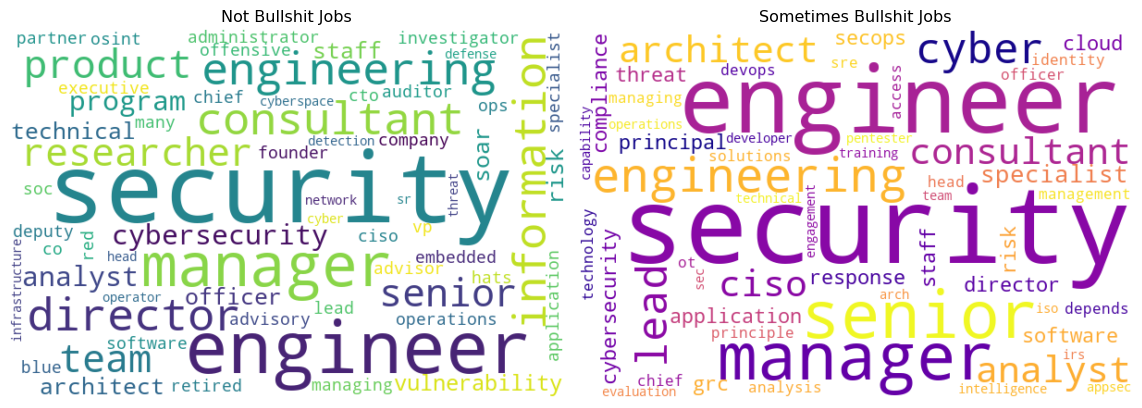

In [23]:
bullshit_col = 'Do you believe your job is a "bullshit job"?'
job_col = "Current Job Title/Role"

not_bullshit = df[df[bullshit_col].str.lower().isin(["no"])]
sometimes_bullshit = df[df[bullshit_col].str.lower().str.contains("sometimes", na=False)]

not_bullshit_jobs = not_bullshit[job_col].dropna().tolist()
sometimes_bullshit_jobs = sometimes_bullshit[job_col].dropna().tolist()

def count_keyword(jobs, keyword):
    return sum(keyword in str(title).lower() for title in jobs)

keywords = ["director", "senior", "ciso", "manager"]

counts = {
    "Title Keyword": [kw.capitalize() for kw in keywords],
    "No (Not Bullshit)": [count_keyword(not_bullshit_jobs, kw) for kw in keywords],
    "Sometimes": [count_keyword(sometimes_bullshit_jobs, kw) for kw in keywords],
}

df_summary = pd.DataFrame(counts)
text_no = " ".join(not_bullshit_jobs).lower()
text_sometimes = " ".join(sometimes_bullshit_jobs).lower()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Word cloud: Not Bullshit Jobs
wc_no = WordCloud(width=600, height=400, background_color="white", colormap="viridis").generate(text_no)
axes[0].imshow(wc_no, interpolation="bilinear")
axes[0].set_title("Not Bullshit Jobs")
axes[0].axis("off")

# Word cloud: Sometimes Bullshit Jobs
wc_sometimes = WordCloud(width=600, height=400, background_color="white", colormap="plasma").generate(text_sometimes)
axes[1].imshow(wc_sometimes, interpolation="bilinear")
axes[1].set_title("Sometimes Bullshit Jobs")
axes[1].axis("off")

plt.tight_layout()
plt.show()

The word clouds compare how respondents described their job titles based on whether they said their job was not a "bullshit job" or was "sometimes" a bullshit job. Each word’s size reflects how often it appeared in the submitted job titles, with larger words representing more common terms.

Across both groups, the most frequent terms cluster around security and engineering roles. Which makes sense given that a majority of respondents work in the tech industry.

Those who felt their job was not a "bullshit job" more often used titles like researcher, product, program, and information, indicating hands-on, technical, or investigative work tied to concrete outcomes. Words such as technical, officer, architect, and team also appear prominently, pointing to roles that feel functional, operational, and collaborative.

In contrast, respondents who said their job was "sometimes" a bullshit job more frequently used titles like consultant, manager, specialist, lead, and compliance. These roles tend to involve oversight, coordination, or advisory responsibilities that may feel more abstract or process-heavy. Terms such as GRC, ISO, and SecOps appear more often in this group, suggesting a stronger association with governance, risk, and policy work.

Seniority markers like senior, director, chief, and principal appear in both groups but are more prominent in the "sometimes" category, hinting that those in higher-level or managerial roles may be more likely to feel that parts of their work lack real impact.

## Conclusion

Across all the analyses, a consistent picture emerges of people who, despite frustrations with bureaucracy, process, and the occasional sense of performative or redundant work, still largely see their jobs as meaningful and valuable. Most respondents believe their work contributes to real outcomes, particularly to the security of people or systems, and that the loss of their role would negatively affect others. The frustration appears to come not from believing their work is pointless, but from how it is structured, managed, or justified within larger organisations.

Differences across gender, income, age, and experience add nuance to that picture rather than overturning it. Higher earners and more senior workers report more bureaucracy, justification, and performative effort, suggesting that as people rise in seniority and salary, they may also become more entangled in systems that create distance from tangible outcomes. Gendered patterns indicate that women and non-binary respondents may feel the weight of bureaucracy more strongly, while still reporting a similar sense of meaning in their work. Age and experience trends show that newer entrants are more likely to feel frustrated or uncertain about the real impact of their work, while more experienced respondents appear to settle into their sense of purpose or find ways to navigate inefficiencies.

Taken together, the results hint at a shared recognition that bullshit is not inherent to the work itself but accumulates through layers of organisational culture, managerialism, and justification. Respondents recognise inefficiencies but still find meaning in problem-solving, collaboration, and contribution.

Several limitations are worth noting. The survey reflects low gender participation, with men making up the majority of responses. This imbalance limits how confidently gender differences can be interpreted and how representative they are of the broader workforce. Early career participation is also low, meaning the experiences of those in their first few years are underrepresented. Their views may offer important insight into how perceptions of meaning and bureaucracy form over time and how they evolve as people move into more senior roles.

Geographically, the data reflects experiences and attitudes primarily from the Anglosphere, particularly Australia, the United Kingdom, and the United States. As a result, we lack a clear understanding of how these sentiments might differ in other regions, such as Asia or mainland Europe, where workplace culture, hierarchy, and concepts of meaningful work can differ significantly.

At the end of the day, the findings suggest that people believe in the purpose of their work but are constrained by systems that make that purpose harder to realise. What is missing is a fuller picture of those systems and the ways that culture, geography, and participation shape how people understand and cope with the contradictions in their work.

If you’d like to dig into the numbers yourself, you can, <a href="/resources/2025-10-InfoSec-Worker-Survey-Normalised-Published.csv" download>download the dataset here</a>.

For slides, recording, zines, and more background on the talk, head over to the
<a href="/soapbox/bullshit-jobs-in-infosec.html">Bullshit Jobs in InfoSec</a> page.

# Bibliography

* [Survey: Women Comprise 22% of the Cybersecurity Workforce](https://www.isc2.org/Insights/2025/03/Women-Comprise-22-percent-of-the-Cybersecurity-Workforce)

# License

<a href="https://garden.errbufferoverfl.me/soapbox/bullshit-jobs-in-infosec.html">Is My Job Even Real? Bullshit Jobs in Infosec</a> © 2025 by <a href="https://garden.errbufferoverfl.me/about.html">errbufferoverfl</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND 4.0</a>